# Milestone 1 – Text → Embedding Baseline
Caption → CLIP tokens (padded/truncated to 77) → per-token hidden states + pooled vector,
using the text encoder from the **same Stable Diffusion checkpoint** the U-Net will use.

**Input:** `manifest.csv` from `01_data_prep` (columns: `image_id`, `file_path`, `caption`).
**Output:** `embeddings/text_embeddings.pt`, `token_stats.csv`, `embedding_config.json`.



## 1. Setup: install libraries and pin versions

In [14]:
!pip -q install diffusers transformers accelerate

from importlib.metadata import version
pkgs = ["torch", "diffusers", "transformers", "accelerate"]
pins = {p: version(p).split("+")[0] for p in pkgs}
print(pins)

with open("requirements.txt", "w") as f:
    for p, v in pins.items():
        f.write(f"{p}=={v}\n")
print(open("requirements.txt").read())


{'torch': '2.11.0', 'diffusers': '0.42.1', 'transformers': '5.22.0', 'accelerate': '1.15.0'}
torch==2.11.0
diffusers==0.42.1
transformers==5.22.0
accelerate==1.15.0

{'torch': '2.11.0', 'diffusers': '0.42.1', 'transformers': '5.22.0', 'accelerate': '1.15.0'}
torch==2.11.0
diffusers==0.42.1
transformers==5.22.0
accelerate==1.15.0



## 2. Environment: Drive, GPU, paths, seed

In [15]:
import json, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path("/content/drive/MyDrive/IE_7615_generative/data")
except ImportError:
    ROOT = Path("./IE_7615_generative/data")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "NO GPU")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda | Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda | Tesla T4


## 3. Load the manifest

In [16]:
MANIFEST = ROOT / "manifest.csv"
if not MANIFEST.exists():
    raise FileNotFoundError(f"{MANIFEST} not found. Run the data-prep notebook first, "
                            "or point ROOT at the folder containing manifest.csv.")

manifest = pd.read_csv(MANIFEST)
captions = manifest["caption"].tolist()
print(manifest.shape)
manifest.head(3)


(2000, 3)


,image_id,file_path,caption
0,139,processed_512/000000000139.png,A woman stands in the dining area at the table.
1,285,processed_512/000000000285.png,A big burly grizzly bear is show with grass in...
2,632,processed_512/000000000632.png,"Bedroom scene with a bookcase, blue comforter ..."


(2000, 3)


,image_id,file_path,caption
0,139,processed_512/000000000139.png,A woman stands in the dining area at the table.
1,285,processed_512/000000000285.png,A big burly grizzly bear is show with grass in...
2,632,processed_512/000000000632.png,"Bedroom scene with a bookcase, blue comforter ..."


## 4. Load CLIP tokenizer and text encoder from the SD checkpoint

In [17]:
from transformers import CLIPTokenizer, CLIPTextModel

CKPT = "stable-diffusion-v1-5/stable-diffusion-v1-5"

tokenizer = CLIPTokenizer.from_pretrained(CKPT, subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained(
    CKPT, subfolder="text_encoder", dtype=torch.float16
).to(device).eval()

MAX_LEN = tokenizer.model_max_length
print("max length:", MAX_LEN, "| hidden size:", text_encoder.config.hidden_size)
print("BOS:", tokenizer.bos_token_id, "| EOS:", tokenizer.eos_token_id, "| PAD:", tokenizer.pad_token_id)


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

max length: 77 | hidden size: 768
BOS: 49406 | EOS: 49407 | PAD: 49407


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

max length: 77 | hidden size: 768
BOS: 49406 | EOS: 49407 | PAD: 49407


## 5. Tokenization of one caption

In [18]:

cap = captions[0]
enc = tokenizer(cap, padding="max_length", max_length=MAX_LEN, truncation=True, return_tensors="pt")
ids = enc.input_ids[0].tolist()

print("caption:", cap)
print("input_ids shape:", tuple(enc.input_ids.shape))
n_real = ids.index(tokenizer.eos_token_id) + 1
print("real tokens (incl. BOS+EOS):", n_real, "| padding tokens:", MAX_LEN - n_real)
print(tokenizer.convert_ids_to_tokens(ids[:n_real]))


caption: A woman stands in the dining area at the table.
input_ids shape: (1, 77)
real tokens (incl. BOS+EOS): 13 | padding tokens: 64
['<|startoftext|>', 'a</w>', 'woman</w>', 'stands</w>', 'in</w>', 'the</w>', 'dining</w>', 'area</w>', 'at</w>', 'the</w>', 'table</w>', '.</w>', '<|endoftext|>']
caption: A woman stands in the dining area at the table.
input_ids shape: (1, 77)
real tokens (incl. BOS+EOS): 13 | padding tokens: 64
['<|startoftext|>', 'a</w>', 'woman</w>', 'stands</w>', 'in</w>', 'the</w>', 'dining</w>', 'area</w>', 'at</w>', 'the</w>', 'table</w>', '.</w>', '<|endoftext|>']


## 6. Embedding function and output shapes

In [19]:
# the core pipeline: captions -> tokens (padded/truncated to 77) -> embeddings.
@torch.no_grad()
def embed(texts):
    tok = tokenizer(texts, padding="max_length", max_length=MAX_LEN,
                    truncation=True, return_tensors="pt")
    out = text_encoder(tok.input_ids.to(device))
    return tok.input_ids, out.last_hidden_state, out.pooler_output

ids_b, hidden, pooled = embed(captions[:4])
print("input_ids         :", tuple(ids_b.shape))
print("last_hidden_state :", tuple(hidden.shape), hidden.dtype)
print("pooler_output     :", tuple(pooled.shape), pooled.dtype)


input_ids         : (4, 77)
last_hidden_state : (4, 77, 768) torch.float16
pooler_output     : (4, 768) torch.float16
input_ids         : (4, 77)
last_hidden_state : (4, 77, 768) torch.float16
pooler_output     : (4, 768) torch.float16


**What the shapes mean**
- `last_hidden_state` `[4, 77, 768]`: one contextual vector per token position. This is what the U-Net's cross-attention layers use as keys and values, so it is the conditioning that matters for Stable Diffusion.
- `pooler_output` `[4, 768]`: the hidden state at the end-of-text token, after the final layer norm. It is a single summary vector per caption. SD 1.x does not use it, but it is handy for comparing captions.
- Positions after the end-of-text token are padding (the pad token is the end-of-text token). SD does not mask them.

In [20]:
# confirm pooled == hidden state at the first EOS position
# argmax over ids finds the first EOS because 49407 is the largest id in the vocab.
eos_pos = ids_b.argmax(dim=-1)
manual = hidden[torch.arange(hidden.size(0)), eos_pos.to(device)]
print("EOS positions:", eos_pos.tolist())
print("pooled == hidden@EOS:", torch.allclose(pooled, manual, atol=1e-3))


EOS positions: [12, 15, 14, 11]
pooled == hidden@EOS: True
EOS positions: [12, 15, 14, 11]
pooled == hidden@EOS: True


## 7. Sanity check: cosine similarity

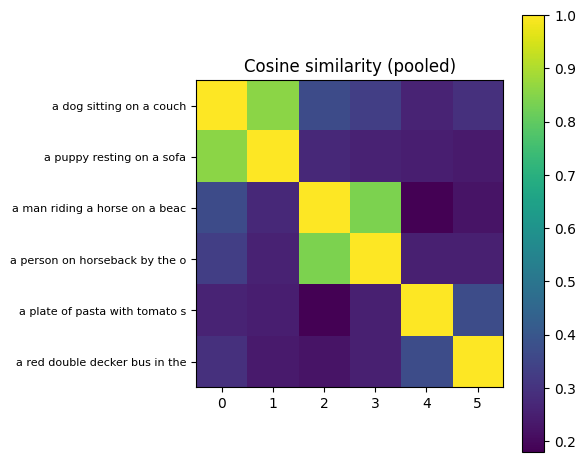

paraphrase A (0,1): 0.856
paraphrase B (2,3): 0.838
unrelated   (0,4): 0.261 | (2,5): 0.223 | (4,5): 0.369


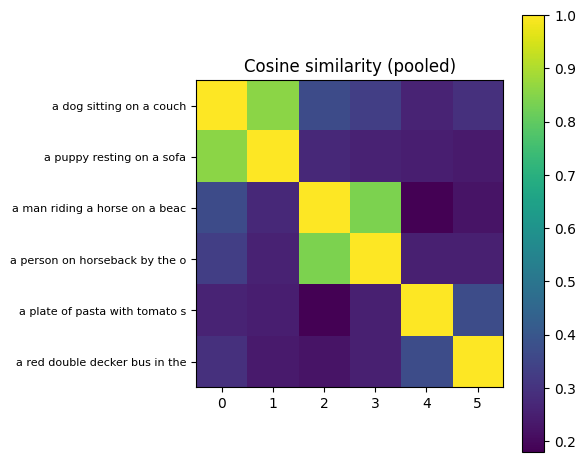

paraphrase A (0,1): 0.856
paraphrase B (2,3): 0.838
unrelated   (0,4): 0.261 | (2,5): 0.223 | (4,5): 0.369


In [21]:
#test on random captions
import torch.nn.functional as F

test = [
    "a dog sitting on a couch",              # 0 \ paraphrase pair A
    "a puppy resting on a sofa",             # 1 /
    "a man riding a horse on a beach",       # 2 \ paraphrase pair B
    "a person on horseback by the ocean",    # 3 /
    "a plate of pasta with tomato sauce",    # 4 unrelated
    "a red double decker bus in the city",   # 5 unrelated
]
_, _, p = embed(test)
p = F.normalize(p.float(), dim=-1)
sim = (p @ p.T).cpu().numpy()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(sim, vmin=sim.min(), vmax=1.0, cmap="viridis")
ax.set_xticks(range(len(test))); ax.set_yticks(range(len(test)))
ax.set_xticklabels(range(len(test))); ax.set_yticklabels([t[:30] for t in test], fontsize=8)
plt.colorbar(im); plt.title("Cosine similarity (pooled)"); plt.tight_layout(); plt.show()

print(f"paraphrase A (0,1): {sim[0,1]:.3f}")
print(f"paraphrase B (2,3): {sim[2,3]:.3f}")
print(f"unrelated   (0,4): {sim[0,4]:.3f} | (2,5): {sim[2,5]:.3f} | (4,5): {sim[4,5]:.3f}")


In [22]:
#same check on real manifest captions: test 1
_, _, p_all_probe = embed(captions[:200])
pn = F.normalize(p_all_probe.float(), dim=-1)
s = (pn[0] @ pn.T).cpu().numpy()
order = s.argsort()[::-1][1:4]
print("query:", captions[0])
for j in order:
    print(f"  {s[j]:.3f}  {captions[j]}")

query: A woman stands in the dining area at the table.
  0.653  A girl with some food and drink at a table.
  0.623  an old woman is in front of some food on a table
  0.601  A group of older people around a long restaurant table.
query: A woman stands in the dining area at the table.
  0.653  A girl with some food and drink at a table.
  0.623  an old woman is in front of some food on a table
  0.601  A group of older people around a long restaurant table.


In [23]:
#same check on real manifest captions: test 2
_, _, p_all_probe = embed(captions[:200])
pn = F.normalize(p_all_probe.float(), dim=-1)
s = (pn[1] @ pn.T).cpu().numpy()
order = s.argsort()[::-1][1:4]
print("query:", captions[1])
for j in order:
    print(f"  {s[j]:.3f}  {captions[j]}")

query: A big burly grizzly bear is show with grass in the background.
  0.472  A sheep standing in grass next to a rock wall.
  0.466  a small sheep is laying in a field
  0.457  A herd of elephants standing on top of a field.
query: A big burly grizzly bear is show with grass in the background.
  0.472  A sheep standing in grass next to a rock wall.
  0.466  a small sheep is laying in a field
  0.457  A herd of elephants standing on top of a field.


In [24]:
#same check on real manifest captions: test 3
_, _, p_all_probe = embed(captions[:200])
pn = F.normalize(p_all_probe.float(), dim=-1)
s = (pn[13] @ pn.T).cpu().numpy()
order = s.argsort()[::-1][1:4]
print("query:", captions[13])
for j in order:
    print(f"  {s[j]:.3f}  {captions[j]}")

query: A large white bowl of many green apples.
  0.525  A bowl filled with lots of oranges on a counter.
  0.504  A collection of apples growing on a tree.
  0.393  A bunch of bananas sitting on top of a wooden table.
query: A large white bowl of many green apples.
  0.525  A bowl filled with lots of oranges on a counter.
  0.504  A collection of apples growing on a tree.
  0.393  A bunch of bananas sitting on top of a wooden table.


## 8. Truncation count and token lengths

Truncated captions: 0 / 2000
count    2000.00000
mean       13.50250
std         2.43474
min         9.00000
25%        12.00000
50%        13.00000
75%        15.00000
max        30.00000
Name: n_tokens, dtype: float64


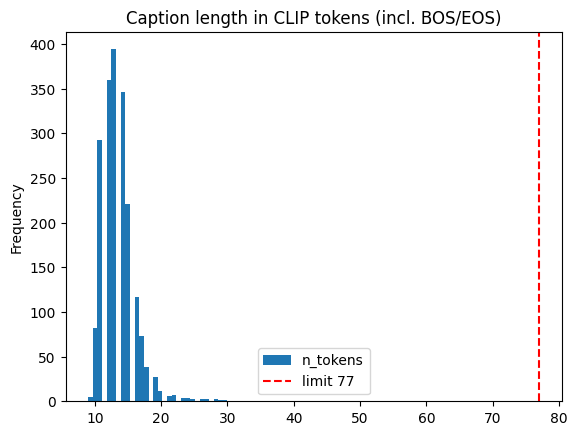

Truncated captions: 0 / 2000
count    2000.00000
mean       13.50250
std         2.43474
min         9.00000
25%        12.00000
50%        13.00000
75%        15.00000
max        30.00000
Name: n_tokens, dtype: float64


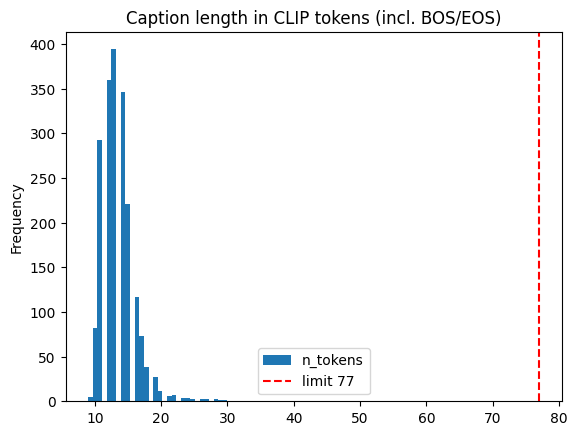

In [25]:
lens = [len(x) for x in tokenizer(captions, truncation=False)["input_ids"]]
manifest["n_tokens"] = lens
manifest["truncated"] = manifest["n_tokens"] > MAX_LEN

print(f"Truncated captions: {manifest['truncated'].sum()} / {len(manifest)}")
print(manifest["n_tokens"].describe())

manifest["n_tokens"].plot.hist(bins=30, title="Caption length in CLIP tokens (incl. BOS/EOS)")
plt.axvline(MAX_LEN, color="red", ls="--", label="limit 77"); plt.legend(); plt.show()


## 9. Embed all captions

In [26]:
from tqdm.auto import tqdm

BATCH = 64
hid_list, pool_list = [], []
for i in tqdm(range(0, len(captions), BATCH)):
    _, h, p = embed(captions[i:i+BATCH])
    hid_list.append(h.cpu()); pool_list.append(p.cpu())

hidden_all = torch.cat(hid_list)    # [2000, 77, 768]
pooled_all = torch.cat(pool_list)   # [2000, 768]

uncond = embed([""])[1].cpu()       # [1, 77, 768]

print(hidden_all.shape, pooled_all.shape, uncond.shape)
print("NaNs:", torch.isnan(hidden_all).any().item())


  0%|          | 0/32 [00:00<?, ?it/s]

torch.Size([2000, 77, 768]) torch.Size([2000, 768]) torch.Size([1, 77, 768])
NaNs: False


  0%|          | 0/32 [00:00<?, ?it/s]

torch.Size([2000, 77, 768]) torch.Size([2000, 768]) torch.Size([1, 77, 768])
NaNs: False


## 10. Save and verify

In [27]:
#save embeddings aligned by image_id, then reload to prove they round-trip.
OUT = ROOT / "embeddings"; OUT.mkdir(exist_ok=True)

torch.save({
    "image_ids": manifest["image_id"].tolist(),   # same row order as hidden/pooled
    "hidden": hidden_all,                          # fp16 [N,77,768]
    "pooled": pooled_all,                          # fp16 [N,768]
    "uncond_hidden": uncond,
    "checkpoint": CKPT,
}, OUT / "text_embeddings.pt")

manifest[["image_id", "n_tokens", "truncated"]].to_csv(OUT / "token_stats.csv", index=False)
with open(OUT / "embedding_config.json", "w") as f:
    json.dump({"checkpoint": CKPT, "n_captions": len(manifest), "max_len": MAX_LEN,
               "n_truncated": int(manifest["truncated"].sum()),
               "max_tokens": int(manifest["n_tokens"].max()),
               "median_tokens": float(manifest["n_tokens"].median())}, f, indent=2)

chk = torch.load(OUT / "text_embeddings.pt")
assert chk["hidden"].shape == (len(manifest), 77, 768)
assert chk["image_ids"] == manifest["image_id"].tolist()
print("saved + verified:", sorted(f.name for f in OUT.iterdir()))



saved + verified: ['embedding_config.json', 'text_embeddings.pt', 'token_stats.csv']


##Summary
- **Checkpoint:** Stable Diffusion v1.5 (`stable-diffusion-v1-5/stable-diffusion-v1-5`), CLIP ViT-L/14 text encoder, 768-d
- **Shapes:** tokens `[B,77]` → per-token hidden states `[B,77,768]`, pooled `[B,768]`
- **Pooled vector:** verified equal to the hidden state at the first end-of-text token
- **Sanity check:** paraphrase pairs ≈ 0.84–0.86 cosine similarity vs ≈ 0.22–0.37 for unrelated pairs
- **Truncation:** 0 / 2000 captions truncated; token lengths mean 13.5, median 13, max 30 (limit 77)
- **Saved:** `embeddings/text_embeddings.pt` (fp16, 2000 × 77 × 768, aligned with the manifest by `image_id`), plus `token_stats.csv`, `embedding_config.json`, and the empty-prompt embedding for classifier-free guidance in Milestone 2
